# 04 — Análisis de coyuntura: inflación en Chile

**Proyecto:** Coyuntura Equipo 06 — Inflación en Chile  
**Pregunta de investigación:** ¿las variables macroeconómicas explicativas mejoran la proyección de la inflación interanual chilena a 12 meses frente a un modelo basado solo en su historia?

Este notebook usa exclusivamente datos reales almacenados en `data/coyuntura.db`, generados desde las APIs oficiales del Banco Central de Chile y FRED. El corte solicitado al pipeline es **2026-10-20**; la última observación varía según el calendario de publicación de cada serie.

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

candidatas = [Path.cwd(), Path.cwd().parent]
RAIZ = next((p for p in candidatas if (p / 'data' / 'coyuntura.db').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('No se encontró data/coyuntura.db. Ejecute primero src/carga_db.py.')

RUTA_DB = RAIZ / 'data' / 'coyuntura.db'
RUTA_SQL = RAIZ / 'sql' / '05_analisis_inflacion_chile.sql'
conn = sqlite3.connect(RUTA_DB)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.labelsize': 10})
pd.options.display.float_format = '{:,.3f}'.format
print(f'Base utilizada: {RUTA_DB}')

Base utilizada: /Users/user/Desktop/ciencia de datos /coyuntura-equipo-06/data/coyuntura.db


## 1. Cobertura y calidad de los datos

La consulta siguiente usa `INNER JOIN`, `GROUP BY` y agregaciones para comprobar la cobertura de las 12 series. `COUNT(valor)` no cuenta los `NULL`, por lo que permite distinguir filas recibidas de observaciones válidas.

In [2]:
sql_cobertura = '''
SELECT
    s.id_serie, s.nombre, s.fuente, s.frecuencia,
    COUNT(o.fecha) AS filas,
    COUNT(o.valor) AS validas,
    COUNT(o.fecha) - COUNT(o.valor) AS faltantes,
    MIN(o.fecha) AS primera_fecha,
    MAX(o.fecha) AS ultima_fecha
FROM series AS s
INNER JOIN observaciones AS o ON o.id_serie = s.id_serie
GROUP BY s.id_serie, s.nombre, s.fuente, s.frecuencia
ORDER BY s.fuente, s.nombre
'''
cobertura = pd.read_sql_query(sql_cobertura, conn)
assert len(cobertura) == 12, f'Se esperaban 12 series y hay {len(cobertura)}'
display(cobertura)

,id_serie,nombre,fuente,frecuencia,filas,validas,faltantes,primera_fecha,ultima_fecha
0,F019.PPB.PRE.100.D,Cobre refinado BML,BCCH,D,5129,3492,1637,2012-10-05,2026-10-20
1,F074.IPC.IND.Z.EP23.C.M,IPC Chile (índice),BCCH,M,201,201,0,2010-01-01,2026-09-01
2,F032.IMC.IND.Z.Z.EP18.Z.Z.0.M,Imacec (índice),BCCH,M,200,200,0,2010-01-01,2026-08-01
3,F019.PPB.PRE.41B.M,Petróleo WTI,BCCH,M,201,201,0,2010-01-01,2026-09-01
4,F022.TPM.TIN.D001.NO.Z.D,Tasa de Política Monetaria (TPM),BCCH,D,6134,4185,1949,2010-01-04,2026-10-20
5,F049.DES.TAS.INE9.10.M,Tasa de desocupación,BCCH,M,198,198,0,2010-03-01,2026-08-01
6,F073.TCO.PRE.Z.D,Tipo de cambio observado (CLP/USD),BCCH,D,6134,4184,1950,2010-01-04,2026-10-20
7,G049.RMM.V12.INE23.NE.M,Índice de remuneraciones (var. anual),BCCH,M,200,200,0,2010-01-01,2026-08-01
8,CPIAUCSL,IPC Estados Unidos (índice),FRED,M,201,200,1,2010-01-01,2026-09-01
9,FEDFUNDS,Tasa Fed Funds (EE.UU.),FRED,M,201,201,0,2010-01-01,2026-09-01


In [3]:
faltantes_frecuencia = (
    cobertura.groupby('frecuencia', as_index=False)
    .agg(series=('id_serie', 'count'), filas=('filas', 'sum'), faltantes=('faltantes', 'sum'))
)
faltantes_frecuencia['porcentaje_faltante'] = (
    100 * faltantes_frecuencia['faltantes'] / faltantes_frecuencia['filas']
)
display(faltantes_frecuencia)
display(Markdown(
    f'**Lectura de faltantes.** La base conserva **{int(cobertura.faltantes.sum()):,}** valores '
    'faltantes como NULL. Se concentran en series diarias: el BCCh devuelve también fechas '
    'sin observación, como fines de semana y feriados. No se imputan valores. En la '
    'mensualización, AVG y COUNT(valor) utilizan solo días efectivamente observados.'
))

,frecuencia,series,filas,faltantes,porcentaje_faltante
0,D,3,17397,5536,31.822
1,M,9,1802,1,0.055


**Lectura de faltantes.** La base conserva **5,537** valores faltantes como NULL. Se concentran en series diarias: el BCCh devuelve también fechas sin observación, como fines de semana y feriados. No se imputan valores. En la mensualización, AVG y COUNT(valor) utilizan solo días efectivamente observados.

### Criterio para homogeneizar frecuencias

El IPC y el Imacec ya son mensuales. La TPM y el tipo de cambio son diarios y se transforman a **promedio mensual de días válidos**, lo que evita dar peso artificial a fines de semana sin dato y representa la exposición media del mes. También se conserva el número de días válidos de cada promedio. Esta decisión es reproducible en `sql/05_analisis_inflacion_chile.sql`; para ejercicios alternativos podría compararse con el último dato hábil del mes.

In [4]:
consulta_analisis = RUTA_SQL.read_text(encoding='utf-8')
df = pd.read_sql_query(consulta_analisis, conn, parse_dates=['fecha'])
df = df.sort_values('fecha').set_index('fecha').asfreq('MS')

# Comprobación independiente en pandas del LAG de 12 meses calculado en SQL.
df['inflacion_calculada_python'] = df['ipc'].pct_change(12, fill_method=None) * 100
comparables = df[['inflacion_interanual', 'inflacion_calculada_python']].dropna()
assert np.allclose(comparables.iloc[:, 0], comparables.iloc[:, 1])

df['imacec_interanual'] = df['imacec'].pct_change(12, fill_method=None) * 100
df['tipo_cambio_interanual'] = df['tipo_cambio_promedio'].pct_change(12, fill_method=None) * 100
print(f'Muestra mensual alineada: {df.index.min():%Y-%m} a {df.index.max():%Y-%m} ({len(df)} meses)')
display(df.tail())

Muestra mensual alineada: 2010-01 a 2026-09 (201 meses)


,ipc,inflacion_interanual,tpm_promedio,tpm_dias_validos,imacec,tipo_cambio_promedio,tipo_cambio_dias_validos,inflacion_calculada_python,imacec_interanual,tipo_cambio_interanual
fecha,,,,,,,,,,
2026-05-01,112.370,3.931,4.500,19,112.106,897.638,19,3.931,-1.387,-4.609
2026-06-01,112.350,4.337,4.500,21,110.601,903.384,21,4.337,2.015,-3.694
2026-07-01,112.450,3.526,4.500,22,106.968,930.970,22,3.526,-1.487,-2.163
2026-08-01,113.150,4.132,4.500,21,109.085,917.663,21,4.132,-1.014,-5.034
2026-09-01,113.590,4.077,4.500,21,NaN,947.267,21,4.077,NaN,-1.364


In [5]:
calidad_alineada = pd.DataFrame({
    'observaciones': df.notna().sum(),
    'faltantes': df.isna().sum(),
    'primera_valida': [df[c].first_valid_index() for c in df.columns],
    'ultima_valida': [df[c].last_valid_index() for c in df.columns],
})
display(calidad_alineada)

,observaciones,faltantes,primera_valida,ultima_valida
ipc,201,0,2010-01-01,2026-09-01
inflacion_interanual,189,12,2011-01-01,2026-09-01
tpm_promedio,201,0,2010-01-01,2026-09-01
tpm_dias_validos,201,0,2010-01-01,2026-09-01
imacec,200,1,2010-01-01,2026-08-01
tipo_cambio_promedio,201,0,2010-01-01,2026-09-01
tipo_cambio_dias_validos,201,0,2010-01-01,2026-09-01
inflacion_calculada_python,189,12,2011-01-01,2026-09-01
imacec_interanual,188,13,2011-01-01,2026-08-01
tipo_cambio_interanual,189,12,2011-01-01,2026-09-01


## 2. IPC e inflación interanual

La inflación interanual se calcula desde el **nivel empalmado del IPC, base 2023=100**, como $100(IPC_t/IPC_{t-12}-1)$. Se obtiene tanto con `LAG` en SQL como con `pct_change(12)` en pandas y se exige que ambos resultados coincidan.

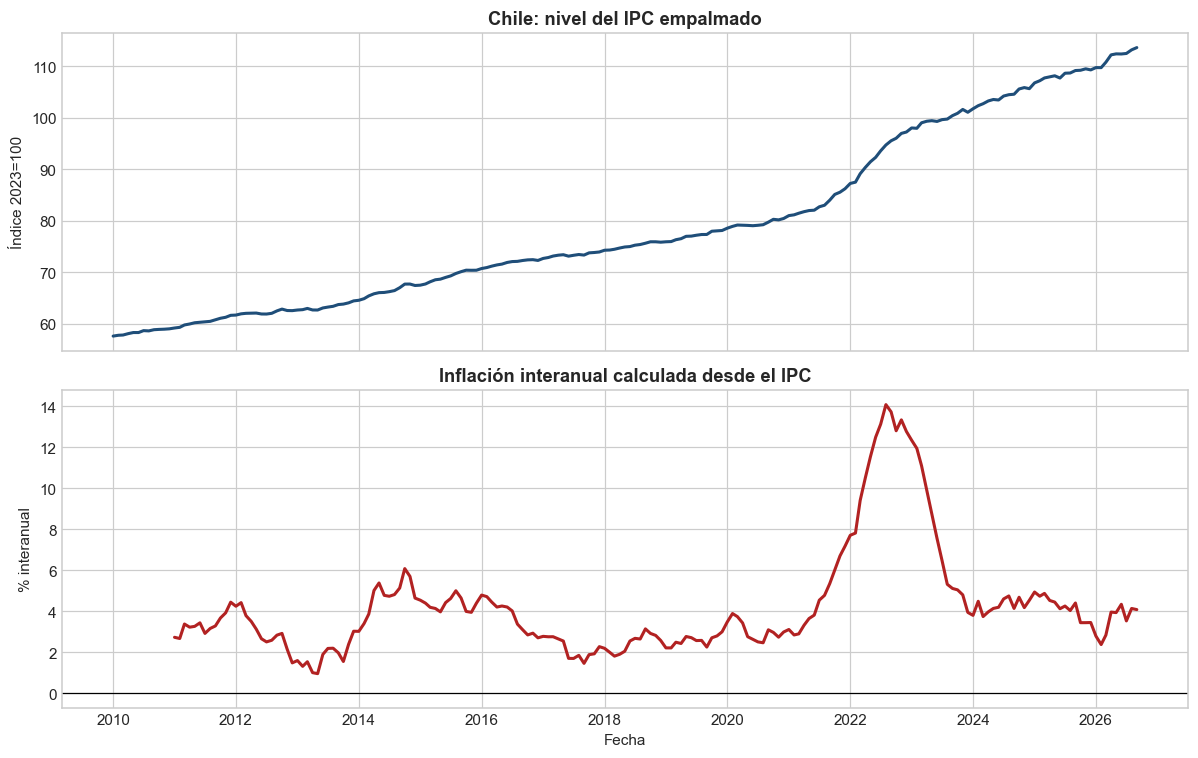

**Interpretación.** La última inflación disponible es **4.08% interanual** en **2026-09**. El máximo de la muestra fue **14.08%** en **2022-08**. El IPC en nivel mantiene una tendencia ascendente, mientras la tasa interanual muestra ciclos marcados; por eso la variable objetivo del pronóstico debe ser la variación interanual y no el nivel sin transformar.

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(df.index, df['ipc'], color='#1f4e79', lw=2)
axes[0].set_title('Chile: nivel del IPC empalmado')
axes[0].set_ylabel('Índice 2023=100')
axes[1].plot(df.index, df['inflacion_interanual'], color='#b22222', lw=2)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_title('Inflación interanual calculada desde el IPC')
axes[1].set_ylabel('% interanual')
axes[1].set_xlabel('Fecha')
fig.tight_layout()
plt.show()

inflacion = df['inflacion_interanual'].dropna()
fecha_pico_inf = inflacion.idxmax()
display(Markdown(
    f'**Interpretación.** La última inflación disponible es **{inflacion.iloc[-1]:.2f}% interanual** '
    f'en **{inflacion.index[-1]:%Y-%m}**. El máximo de la muestra fue '
    f'**{inflacion.max():.2f}%** en **{fecha_pico_inf:%Y-%m}**. El IPC en nivel '
    'mantiene una tendencia ascendente, mientras la tasa interanual muestra ciclos marcados; '
    'por eso la variable objetivo del pronóstico debe ser la variación interanual y no el nivel sin transformar.'
))

## 3. Política monetaria: TPM e inflación

La TPM mensual corresponde al promedio de los registros diarios válidos. Se presenta junto con la inflación para estudiar su comovimiento, sin interpretar la asociación como un efecto causal identificado.

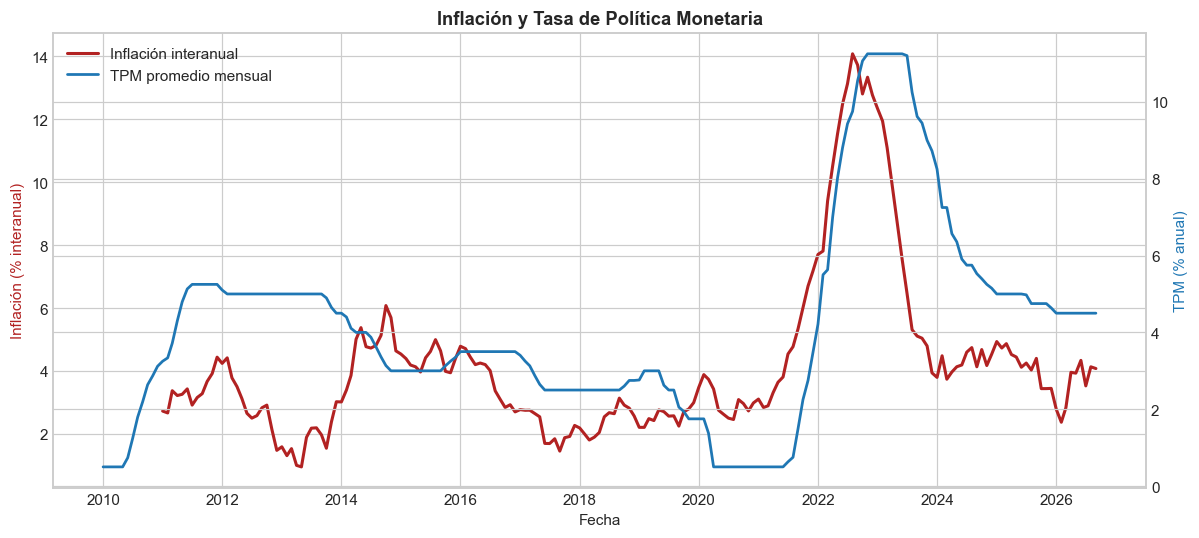

**Interpretación.** La TPM mensual más reciente es **4.50%** (2026-09); su máximo fue **11.25%** en 2022-11. La correlación contemporánea con la inflación es **0.67**. El signo positivo es compatible con una autoridad que eleva la tasa cuando la inflación ya es alta; por sí solo no demuestra que una TPM mayor cause más inflación. Para pronosticar se usarán rezagos y evaluación fuera de muestra.

In [7]:
fig, ax_inf = plt.subplots(figsize=(11, 5))
ax_tpm = ax_inf.twinx()
l1 = ax_inf.plot(df.index, df['inflacion_interanual'], color='#b22222', lw=2, label='Inflación interanual')
l2 = ax_tpm.plot(df.index, df['tpm_promedio'], color='#1f77b4', lw=1.8, label='TPM promedio mensual')
ax_inf.set_title('Inflación y Tasa de Política Monetaria')
ax_inf.set_ylabel('Inflación (% interanual)', color='#b22222')
ax_tpm.set_ylabel('TPM (% anual)', color='#1f77b4')
ax_inf.set_xlabel('Fecha')
ax_inf.legend(l1 + l2, [x.get_label() for x in l1 + l2], loc='upper left')
fig.tight_layout()
plt.show()

tpm = df['tpm_promedio'].dropna()
corr_tpm = df[['inflacion_interanual', 'tpm_promedio']].corr().iloc[0, 1]
display(Markdown(
    f'**Interpretación.** La TPM mensual más reciente es **{tpm.iloc[-1]:.2f}%** '
    f'({tpm.index[-1]:%Y-%m}); su máximo fue **{tpm.max():.2f}%** en '
    f'{tpm.idxmax():%Y-%m}. La correlación contemporánea con la inflación es '
    f'**{corr_tpm:.2f}**. El signo positivo es compatible con una autoridad que eleva la tasa '
    'cuando la inflación ya es alta; por sí solo no demuestra que una TPM mayor cause más inflación. '
    'Para pronosticar se usarán rezagos y evaluación fuera de muestra.'
))

## 4. Actividad económica: Imacec

Se conserva el índice original del Imacec y se calcula su variación interanual para obtener una medida de dinamismo más comparable a la inflación.

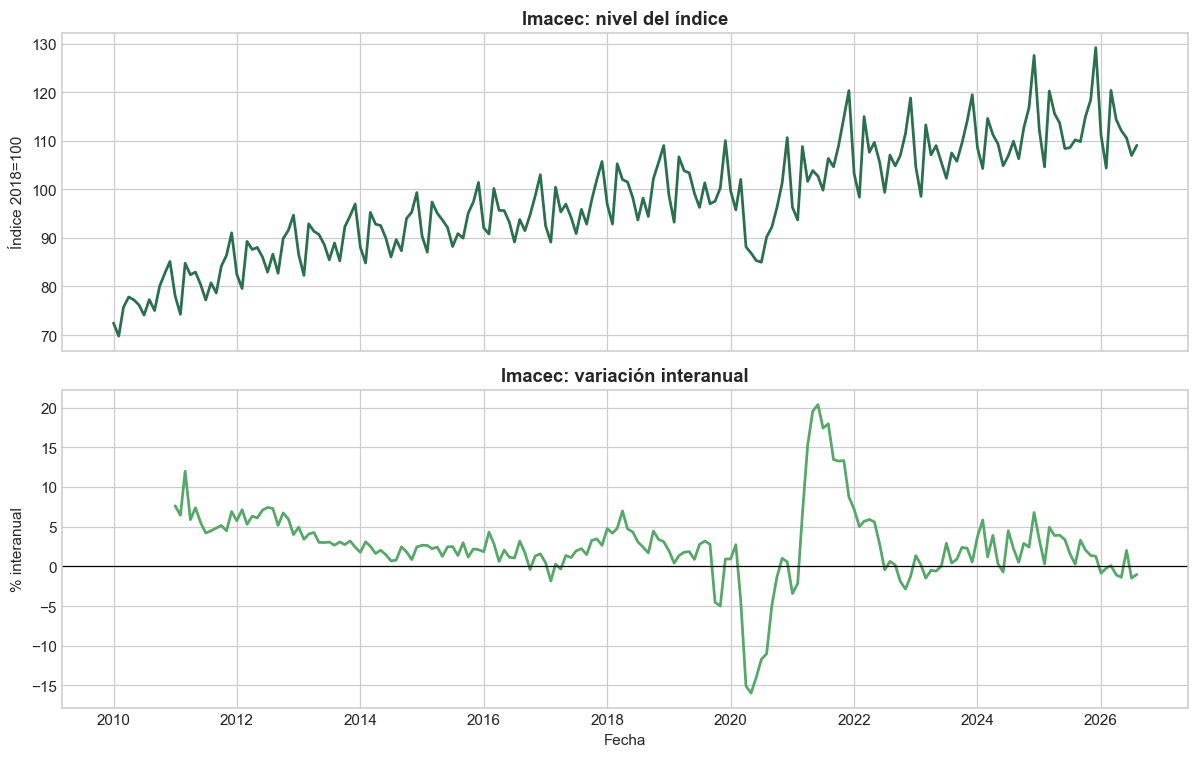

**Interpretación.** La última variación del Imacec disponible es **-1.01% interanual** en **2026-08**. La muestra registra un mínimo de **-15.98%** en 2020-05 y un máximo de **20.38%** en 2021-06. Los extremos asociados a la pandemia y su rebote advierten que los modelos deben ser robustos a quiebres y efectos base.

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(df.index, df['imacec'], color='#2a6f4e', lw=1.8)
axes[0].set_title('Imacec: nivel del índice')
axes[0].set_ylabel('Índice 2018=100')
axes[1].plot(df.index, df['imacec_interanual'], color='#55a868', lw=1.8)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_title('Imacec: variación interanual')
axes[1].set_ylabel('% interanual')
axes[1].set_xlabel('Fecha')
fig.tight_layout()
plt.show()

imacec_ia = df['imacec_interanual'].dropna()
display(Markdown(
    f'**Interpretación.** La última variación del Imacec disponible es **{imacec_ia.iloc[-1]:.2f}% '
    f'interanual** en **{imacec_ia.index[-1]:%Y-%m}**. La muestra registra un mínimo de '
    f'**{imacec_ia.min():.2f}%** en {imacec_ia.idxmin():%Y-%m} y un máximo de '
    f'**{imacec_ia.max():.2f}%** en {imacec_ia.idxmax():%Y-%m}. Los extremos asociados a la '
    'pandemia y su rebote advierten que los modelos deben ser robustos a quiebres y efectos base.'
))

## 5. Factor externo: tipo de cambio observado

El tipo de cambio se mensualiza mediante el promedio de días hábiles con dato. También se calcula su variación interanual; un valor positivo representa una depreciación del peso frente al dólar.

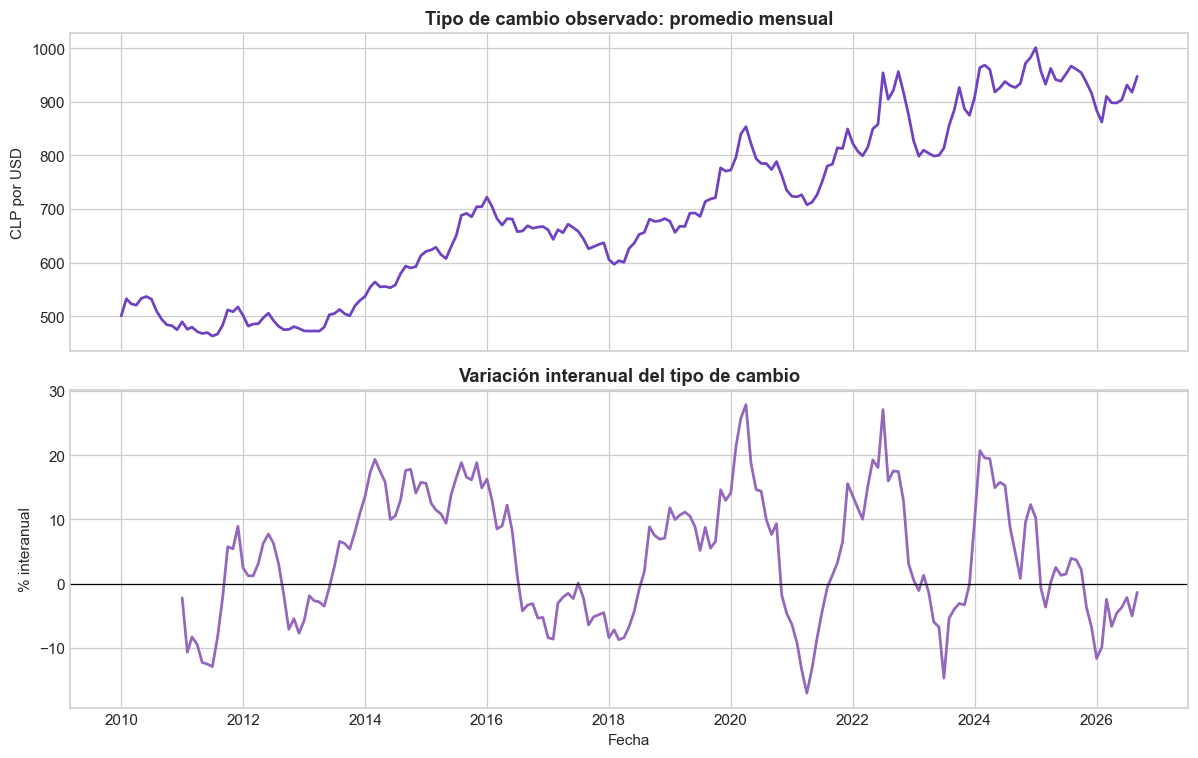

**Interpretación.** El último promedio mensual disponible es **$947.3 CLP/USD** en **2026-09**, con una variación interanual de **-1.36%**. El máximo promedio mensual de la muestra fue $1,000.8 en 2025-01. Una depreciación puede traspasarse a precios importados con rezagos, pero la magnitud depende de costos, márgenes, demanda y política monetaria.

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(df.index, df['tipo_cambio_promedio'], color='#6f42c1', lw=1.8)
axes[0].set_title('Tipo de cambio observado: promedio mensual')
axes[0].set_ylabel('CLP por USD')
axes[1].plot(df.index, df['tipo_cambio_interanual'], color='#9467bd', lw=1.8)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_title('Variación interanual del tipo de cambio')
axes[1].set_ylabel('% interanual')
axes[1].set_xlabel('Fecha')
fig.tight_layout()
plt.show()

tc = df['tipo_cambio_promedio'].dropna()
tc_ia = df['tipo_cambio_interanual'].dropna()
display(Markdown(
    f'**Interpretación.** El último promedio mensual disponible es **${tc.iloc[-1]:,.1f} CLP/USD** '
    f'en **{tc.index[-1]:%Y-%m}**, con una variación interanual de '
    f'**{tc_ia.iloc[-1]:.2f}%**. El máximo promedio mensual de la muestra fue '
    f'${tc.max():,.1f} en {tc.idxmax():%Y-%m}. Una depreciación puede traspasarse a precios '
    'importados con rezagos, pero la magnitud depende de costos, márgenes, demanda y política monetaria.'
))

## 6. Relaciones con la inflación y horizonte de 12 meses

Para conectar la coyuntura con la pregunta de investigación, se compara la correlación contemporánea con la correlación entre información disponible en $t$ y la inflación observada en $t+12$. La inflación corriente representa la información de un benchmark autorregresivo. Este ejercicio es exploratorio: no reemplaza la evaluación predictiva fuera de muestra ni identifica causalidad.

,Inflación en t,Inflación en t+12
Inflación actual,1.000,0.325
TPM,0.673,-0.045
Imacec a/a,-0.025,0.428
TC a/a,0.321,0.034


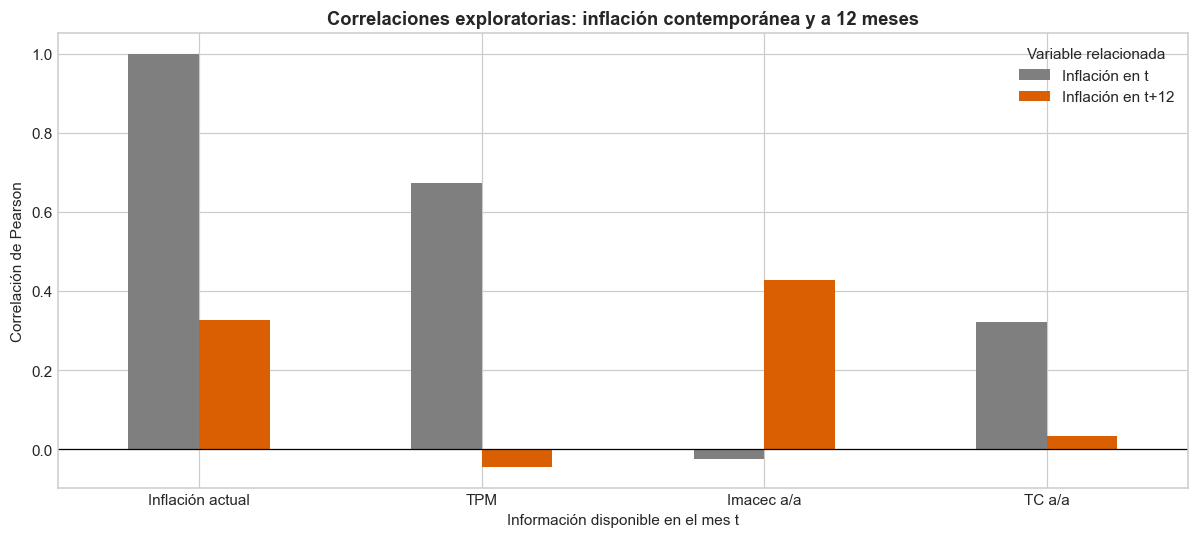

**Interpretación.** En esta muestra, la asociación lineal más alta entre una variable macroeconómica en $t$ y la inflación en $t+12$ corresponde a **Imacec a/a**, con correlación **0.43** y 177 pares mensuales. La propia inflación actual presenta una correlación de **0.33** con la inflación doce meses después. Estas asociaciones sugieren variables candidatas, pero no permiten concluir mejora predictiva ni causalidad: esa conclusión exige comparar errores fuera de muestra bajo el mismo esquema temporal.

In [10]:
modelo = df[[
    'inflacion_interanual', 'tpm_promedio',
    'imacec_interanual', 'tipo_cambio_interanual'
]].copy()
modelo['inflacion_objetivo_t12'] = modelo['inflacion_interanual'].shift(-12)

nombres = {
    'inflacion_interanual': 'Inflación actual',
    'tpm_promedio': 'TPM',
    'imacec_interanual': 'Imacec a/a',
    'tipo_cambio_interanual': 'TC a/a',
}
predictores = list(nombres)
corr_actual = modelo[predictores].corrwith(modelo['inflacion_interanual'])
corr_futura = modelo[predictores].corrwith(modelo['inflacion_objetivo_t12'])
tabla_corr = pd.DataFrame({
    'Inflación en t': corr_actual,
    'Inflación en t+12': corr_futura,
}).rename(index=nombres)
display(tabla_corr.round(3))

ax = tabla_corr.plot(kind='bar', figsize=(11, 5), color=['#7f7f7f', '#d95f02'])
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Correlaciones exploratorias: inflación contemporánea y a 12 meses')
ax.set_ylabel('Correlación de Pearson')
ax.set_xlabel('Información disponible en el mes t')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Variable relacionada')
plt.tight_layout()
plt.show()

corr_macro_futura = corr_futura.drop('inflacion_interanual')
mejor = corr_macro_futura.abs().idxmax()
pares_mejor = modelo[[mejor, 'inflacion_objetivo_t12']].dropna()
display(Markdown(
    f'**Interpretación.** En esta muestra, la asociación lineal más alta entre una variable '
    f'macroeconómica en $t$ y la inflación en $t+12$ corresponde a **{nombres[mejor]}**, '
    f'con correlación **{corr_macro_futura[mejor]:.2f}** y {len(pares_mejor)} pares mensuales. '
    f'La propia inflación actual presenta una correlación de **{corr_futura.inflacion_interanual:.2f}** '
    'con la inflación doce meses después. Estas asociaciones sugieren variables candidatas, pero '
    'no permiten concluir mejora predictiva ni causalidad: esa conclusión exige comparar errores '
    'fuera de muestra bajo el mismo esquema temporal.'
))

In [11]:
dataset_modelo = modelo.dropna().copy()
resumen_modelo = pd.DataFrame({
    'filas_completas': [len(dataset_modelo)],
    'desde': [dataset_modelo.index.min()],
    'hasta_predictor': [dataset_modelo.index.max()],
    'horizonte_objetivo_meses': [12],
})
display(resumen_modelo)
display(dataset_modelo.tail())

,filas_completas,desde,hasta_predictor,horizonte_objetivo_meses
0,177,2011-01-01,2025-09-01,12


,inflacion_interanual,tpm_promedio,imacec_interanual,tipo_cambio_interanual,inflacion_objetivo_t12
fecha,,,,,
2025-05-01,4.444,5.000,3.933,2.521,3.931
2025-06-01,4.119,5.000,3.376,1.291,4.337
2025-07-01,4.252,4.977,1.597,1.492,3.526
2025-08-01,4.031,4.750,0.270,3.915,4.132
2025-09-01,4.400,4.750,3.296,3.687,4.077


## 7. Comparación predictiva preliminar a 12 meses

Se realiza un backtest de origen móvil para 36 pronósticos conocidos. El modelo base es una regresión Ridge directa con inflación actual y rezagos 1, 3, 6 y 12. El modelo ampliado agrega TPM, crecimiento del Imacec y variación del tipo de cambio, todos rezagados un mes para ser conservadores respecto de su disponibilidad. En cada origen solo se entrena con objetivos que ya habrían sido observados; el escalamiento se estima nuevamente dentro de cada muestra de entrenamiento. También se informa un benchmark ingenuo que proyecta la inflación actual.

,RMSE,MAE
modelo,,
Ingenuo,3.690,2.340
Solo inflación,2.716,2.077
Inflación + macro,5.465,4.310


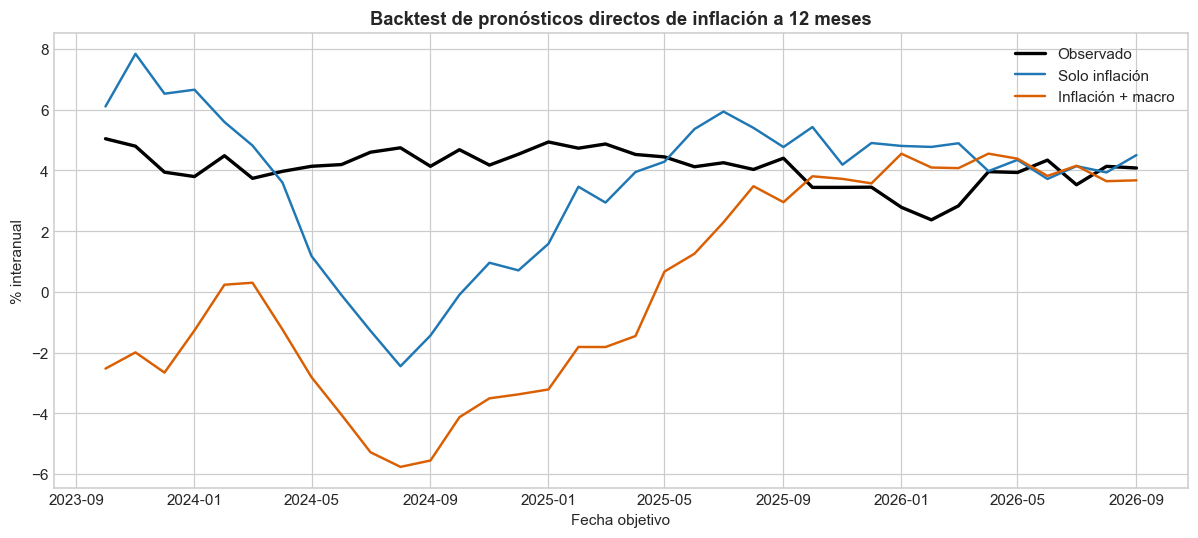

**Resultado predictivo preliminar.** En los 36 pronósticos con fechas objetivo entre **2023-10** y **2026-09**, el modelo de solo inflación obtiene RMSE **2.716**, mientras el modelo ampliado obtiene **5.465**: la incorporación macroeconómica deteriora el RMSE en **101.2%** bajo esta especificación. Este resultado es pseudo-fuera-de-muestra y no una conclusión causal ni definitiva: usa datos revisados, una única penalización y una selección acotada de rezagos.

,inflacion_proyectada_pct,origen,fecha_objetivo
modelo,,,
Ingenuo,4.077,2026-09-01,2027-09-01
Solo inflación,4.670,2026-09-01,2027-09-01
Inflación + macro,4.266,2026-09-01,2027-09-01


**Proyección condicional.** Según el menor RMSE del backtest, se selecciona **Solo inflación**. Con información hasta **2026-09**, este modelo proyecta una inflación de **4.67% interanual** para **2027-09**. La cifra es una proyección estadística sujeta a la especificación y a revisiones de datos; no es un escenario causal ni incorpora shocks futuros no observados.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

backtest = df.copy()
for rezago in [1, 3, 6, 12]:
    backtest[f'inflacion_lag_{rezago}'] = backtest['inflacion_interanual'].shift(rezago)
for variable in ['tpm_promedio', 'imacec_interanual', 'tipo_cambio_interanual']:
    backtest[f'{variable}_lag_1'] = backtest[variable].shift(1)
backtest['objetivo_t12'] = backtest['inflacion_interanual'].shift(-12)

variables_base = [
    'inflacion_interanual', 'inflacion_lag_1', 'inflacion_lag_3',
    'inflacion_lag_6', 'inflacion_lag_12'
]
variables_macro = variables_base + [
    'tpm_promedio_lag_1', 'imacec_interanual_lag_1',
    'tipo_cambio_interanual_lag_1'
]
datos_backtest = backtest[variables_macro + ['objetivo_t12']].dropna()
origenes = datos_backtest.index[-36:]
pronosticos = []

for origen in origenes:
    # Para un pronóstico emitido en t, solo se usan filas cuyo objetivo t+12
    # ya era observable en t. Esto evita look-ahead bias en el entrenamiento.
    entrenamiento = datos_backtest.loc[
        datos_backtest.index <= origen - pd.DateOffset(months=12)
    ]
    prueba = datos_backtest.loc[[origen]]
    assert ((entrenamiento.index + pd.DateOffset(months=12)) <= origen).all()

    fila = {
        'origen': origen,
        'fecha_objetivo': origen + pd.DateOffset(months=12),
        'observado': prueba['objetivo_t12'].iloc[0],
        'Ingenuo': prueba['inflacion_interanual'].iloc[0],
        'n_entrenamiento': len(entrenamiento),
    }
    for nombre, variables in [('Solo inflación', variables_base), ('Inflación + macro', variables_macro)]:
        estimador = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        estimador.fit(entrenamiento[variables], entrenamiento['objetivo_t12'])
        fila[nombre] = estimador.predict(prueba[variables])[0]
    pronosticos.append(fila)

pronosticos = pd.DataFrame(pronosticos).set_index('fecha_objetivo')
metricas = []
for nombre in ['Ingenuo', 'Solo inflación', 'Inflación + macro']:
    metricas.append({
        'modelo': nombre,
        'RMSE': mean_squared_error(pronosticos['observado'], pronosticos[nombre]) ** 0.5,
        'MAE': mean_absolute_error(pronosticos['observado'], pronosticos[nombre]),
    })
metricas = pd.DataFrame(metricas).set_index('modelo')
display(metricas.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(pronosticos.index, pronosticos['observado'], color='black', lw=2.2, label='Observado')
ax.plot(pronosticos.index, pronosticos['Solo inflación'], color='#1f77b4', lw=1.6, label='Solo inflación')
ax.plot(pronosticos.index, pronosticos['Inflación + macro'], color='#d95f02', lw=1.6, label='Inflación + macro')
ax.set_title('Backtest de pronósticos directos de inflación a 12 meses')
ax.set_ylabel('% interanual')
ax.set_xlabel('Fecha objetivo')
ax.legend()
fig.tight_layout()
plt.show()

rmse_base = metricas.loc['Solo inflación', 'RMSE']
rmse_macro = metricas.loc['Inflación + macro', 'RMSE']
cambio_rmse = 100 * (rmse_macro / rmse_base - 1)
resultado = 'mejora' if cambio_rmse < 0 else 'deteriora'
display(Markdown(
    f'**Resultado predictivo preliminar.** En los 36 pronósticos con fechas objetivo entre '
    f'**{pronosticos.index.min():%Y-%m}** y **{pronosticos.index.max():%Y-%m}**, el modelo de '
    f'solo inflación obtiene RMSE **{rmse_base:.3f}**, mientras el modelo ampliado obtiene '
    f'**{rmse_macro:.3f}**: la incorporación macroeconómica {resultado} el RMSE en '
    f'**{abs(cambio_rmse):.1f}%** bajo esta especificación. Este resultado es pseudo-fuera-de-muestra '
    'y no una conclusión causal ni definitiva: usa datos revisados, una única penalización y una '
    'selección acotada de rezagos.'
)),

# Proyección condicional final a 12 meses con toda la información disponible.
entrenamiento_final = datos_backtest
x_final = backtest[variables_macro].dropna().iloc[[-1]]
origen_final = x_final.index[0]
fecha_proyectada = origen_final + pd.DateOffset(months=12)
proyecciones_finales = {
    'Ingenuo': x_final['inflacion_interanual'].iloc[0],
}
for nombre, variables in [('Solo inflación', variables_base), ('Inflación + macro', variables_macro)]:
    estimador = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    estimador.fit(entrenamiento_final[variables], entrenamiento_final['objetivo_t12'])
    proyecciones_finales[nombre] = estimador.predict(x_final[variables])[0]

tabla_proyeccion = pd.DataFrame({
    'modelo': list(proyecciones_finales),
    'inflacion_proyectada_pct': list(proyecciones_finales.values()),
    'origen': origen_final,
    'fecha_objetivo': fecha_proyectada,
}).set_index('modelo')
display(tabla_proyeccion.round(3))

modelo_seleccionado = metricas.loc[['Solo inflación', 'Inflación + macro'], 'RMSE'].idxmin()
display(Markdown(
    f'**Proyección condicional.** Según el menor RMSE del backtest, se selecciona **{modelo_seleccionado}**. '
    f'Con información hasta **{origen_final:%Y-%m}**, este modelo proyecta una inflación de '
    f'**{proyecciones_finales[modelo_seleccionado]:.2f}% interanual** para **{fecha_proyectada:%Y-%m}**. '
    'La cifra es una proyección estadística sujeta a la especificación y a revisiones de datos; no '
    'es un escenario causal ni incorpora shocks futuros no observados.'
))

## 8. Conclusiones para la estrategia de proyección

- El nivel correcto del IPC permite construir de forma transparente la inflación interanual, que será la variable objetivo.
- TPM, crecimiento interanual del Imacec y variación interanual del tipo de cambio están alineados a frecuencia mensual sin imputación silenciosa.
- Las correlaciones contemporáneas pueden reflejar simultaneidad o respuesta de política; no deben interpretarse como causalidad.
- En la comparación preliminar de 36 pronósticos, el modelo ampliado no supera al modelo basado solo en la historia de la inflación. Esto es un resultado válido: agregar variables no garantiza menor error.
- La proyección final a 12 meses se toma del modelo con menor RMSE del backtest y se reporta como condicional, no como certeza.
- La tabla `dataset_modelo` deja preparada la muestra para probar especificaciones alternativas sin imputación silenciosa.
- La selección final debe basarse en RMSE/MAE fuera de muestra y no en el ajuste dentro de muestra ni en correlaciones aisladas.

In [13]:
conn.close()
print('Conexión SQLite cerrada. Análisis ejecutado correctamente.')

Conexión SQLite cerrada. Análisis ejecutado correctamente.
